# Step 9 — Player count

**Three sizes of field, each with an exact answer to check against.** The same agent, the
same architecture, the same `terminal` reward and the same `ranked` seating, trained
separately at $N=3$, $N=5$ and $N=7$.

**Why this comes last.** Every earlier step holds the player count fixed and moves something
else. This one moves the size of the field, which changes more of the game than any other
dial: the circle is longer, the contraction has further to run, and a player's two
neighbours are a smaller share of the whole. It belongs after the method is established
because it asks whether the method's answer was about the game or about one size of it.

**The one thing to get right.** Three player counts give three exact answers, and they do
**not** line up in a straight line. Reporting three separate results would miss the finding;
reporting a straight-line trend would invent one. The exact answers themselves rise and then
fall, so an agent that tracks them has to rise and then fall too.

**The two explanations make opposite predictions here, which is what makes the step worth
running.** An agent that has found the equilibrium should show the weakest player's
advantage *peak at $N=5$ and come back down at $N=7$*. An agent that has drifted onto
`shoot_strongest` should show it *climbing at every step*. One number separates them.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn

from gruel_env import GruelEnv, MISS, SHOOT_LEFT, SHOOT_RIGHT, N_ACTIONS

PLAYER_COUNTS = [3, 5, 7]
SEED = 0
REWARD = "terminal"
SEATING = "ranked"

torch.set_num_threads(1)

print("torch", torch.__version__)
print("player counts:", PLAYER_COUNTS)
print("reward:", REWARD, " seating:", SEATING)

torch 2.2.2
player counts: [3, 5, 7]
reward: terminal  seating: ranked


## The exact answers this folder carries

**Written weakest-first, by rank rather than by accuracy.** Under `ranked` seating position
$i$ holds the $i$-th weakest accuracy, so a rank-ordered list is unambiguous. Keying the
table on the accuracy *values* would be fragile here in a way it was not at $N=5$: at $N=7$
the accuracies are $0.4 + 0.4i/6$, which are not round numbers, and a typed literal like
`0.4667` is not the same float the environment computes. So the accuracies come from the
environment and only the survival numbers are written down.

**These are quoted from folder 02, not solved here.** This folder trains agents; it does not
contain a solver. Folder `02-exact-solver` derives them, and no folder may import another, so
they are typed in, and the borrowing is stated rather than hidden.

In [2]:
# Exact equilibrium survival, weakest rank first.
EXACT_BY_RANK = {
    3: [0.37037, 0.33333, 0.29630],
    5: [0.24959, 0.21073, 0.17970, 0.16194, 0.19804],
    7: [0.15335, 0.17343, 0.14916, 0.13761, 0.12996, 0.13217, 0.12432],
}

# The player counts an exact answer exists for at all — a fact about the game, established in
# folder 02, which reaches N=8 and is refused at N=9 because no pure equilibrium exists there.
EXACT_ANSWERS_EXIST_FOR = {3, 4, 5, 6, 7, 8}

# The player counts THIS folder carries a profile for, which is a smaller set. The two are
# deliberately separate questions: the first is about the game, the second about this folder.
EXACT_PROFILES_CARRIED = set(EXACT_BY_RANK)

for n in PLAYER_COUNTS:
    total = sum(EXACT_BY_RANK[n])
    print("N=%d  %d ranks, sums to %.5f" % (n, len(EXACT_BY_RANK[n]), total))

print()
print("exact answers exist for:      ", sorted(EXACT_ANSWERS_EXIST_FOR))
print("profiles carried in this step:", sorted(EXACT_PROFILES_CARRIED))

N=3  3 ranks, sums to 1.00000
N=5  5 ranks, sums to 1.00000
N=7  7 ranks, sums to 1.00000

exact answers exist for:       [3, 4, 5, 6, 7, 8]
profiles carried in this step: [3, 5, 7]


## Pairing the exact numbers with the environment's own accuracies

The rank-ordered list is turned into a table keyed the same way the measurement is, by
rounding the environment's accuracies to four decimals. That way the exact table and the
measured table cannot disagree about what a key means.

In [3]:
def accuracies_of(n):
    game = GruelEnv(n=n, reward=REWARD, seating=SEATING, seed=0)
    game.reset(seed=0)
    return [round(float(a), 4) for a in game.accuracies]


def exact_table(n):
    seated = accuracies_of(n)
    ranked = sorted(seated)
    if len(ranked) != len(EXACT_BY_RANK[n]):
        raise ValueError("exact list length does not match the player count")
    table = {}
    for rank in range(len(ranked)):
        table[ranked[rank]] = EXACT_BY_RANK[n][rank]
    return table


EXACT = {}
ACCURACIES = {}
for n in PLAYER_COUNTS:
    EXACT[n] = exact_table(n)
    ACCURACIES[n] = accuracies_of(n)

for n in PLAYER_COUNTS:
    print("N=%d" % n)
    print("    accuracies:", ACCURACIES[n])
    print("    ascending? ", ACCURACIES[n] == sorted(ACCURACIES[n]))
    print("    exact:     ", [EXACT[n][a] for a in sorted(EXACT[n])])

N=3
    accuracies: [0.4, 0.6, 0.8]
    ascending?  True
    exact:      [0.37037, 0.33333, 0.2963]
N=5
    accuracies: [0.4, 0.5, 0.6, 0.7, 0.8]
    ascending?  True
    exact:      [0.24959, 0.21073, 0.1797, 0.16194, 0.19804]
N=7
    accuracies: [0.4, 0.4667, 0.5333, 0.6, 0.6667, 0.7333, 0.8]
    ascending?  True
    exact:      [0.15335, 0.17343, 0.14916, 0.13761, 0.12996, 0.13217, 0.12432]


## The three exact answers are three different shapes

This is the fact the whole step rests on, so it is derived from the tables rather than
described. If all three had the same shape, one player count would have answered the
question and there would be no reason to train three times.

In [4]:
print("%-4s %-10s %-32s %-32s" % ("N", "even 1/N", "best off", "worst off"))
for n in PLAYER_COUNTS:
    ranked = [EXACT[n][a] for a in sorted(EXACT[n])]
    best = max(range(len(ranked)), key=lambda i: ranked[i])
    worst = min(range(len(ranked)), key=lambda i: ranked[i])
    label = {0: "rank 0, the weakest"}
    best_label = label.get(best, "rank %d" % best)
    worst_label = "rank %d" % worst
    if worst == len(ranked) - 1:
        worst_label = worst_label + ", the strongest"
    if worst == 0:
        worst_label = worst_label + ", the weakest"
    print("%-4d %-10.5f %-32s %-32s" % (n, 1.0 / n, best_label + " (%.5f)" % ranked[best],
                                        worst_label + " (%.5f)" % ranked[worst]))

print()
shapes = []
for n in PLAYER_COUNTS:
    ranked = [EXACT[n][a] for a in sorted(EXACT[n])]
    best = max(range(len(ranked)), key=lambda i: ranked[i])
    worst = min(range(len(ranked)), key=lambda i: ranked[i])
    shapes.append((best, worst))
print("(best-off rank, worst-off rank) per N:", shapes)
print("all three the same shape?", len(set(shapes)) == 1)

N    even 1/N   best off                         worst off                       
3    0.33333    rank 0, the weakest (0.37037)    rank 2, the strongest (0.29630) 
5    0.20000    rank 0, the weakest (0.24959)    rank 3 (0.16194)                
7    0.14286    rank 1 (0.17343)                 rank 6, the strongest (0.12432) 

(best-off rank, worst-off rank) per N: [(0, 2), (0, 3), (1, 6)]
all three the same shape? False


**Read the three rows as three different games.** At $N=3$ the weakest is best off and the
strongest worst — the ordering runs straight down. At $N=5$ the weakest is still best off but
the *second-strongest* is worst, so the ordering has a kink in it. At $N=7$ the weakest is no
longer even the best-off player, and the worst place to sit is the strongest seat.

**So "survival of the weakest" is not one claim repeated three times.** It weakens, and where
it weakens is exactly what an agent has to reproduce.

In [5]:
UNIFORM = {}
for n in PLAYER_COUNTS:
    UNIFORM[n] = 1.0 / n

print("%-4s %-12s %-12s %-12s" % ("N", "weakest", "even share", "ratio"))
for n in PLAYER_COUNTS:
    weakest = EXACT[n][sorted(EXACT[n])[0]]
    print("%-4d %-12.5f %-12.5f %-12.4f" % (n, weakest, UNIFORM[n], weakest / UNIFORM[n]))

print()
exact_ratios = []
for n in PLAYER_COUNTS:
    weakest = EXACT[n][sorted(EXACT[n])[0]]
    exact_ratios.append(weakest / UNIFORM[n])
print("exact ratio rises from N=3 to N=5? ", exact_ratios[1] > exact_ratios[0])
print("exact ratio falls from N=5 to N=7? ", exact_ratios[2] < exact_ratios[1])
print("so the exact answer is NOT monotone in N:", not (exact_ratios[0] < exact_ratios[1] < exact_ratios[2]))

N    weakest      even share   ratio       
3    0.37037      0.33333      1.1111      
5    0.24959      0.20000      1.2479      
7    0.15335      0.14286      1.0735      

exact ratio rises from N=3 to N=5?  True
exact ratio falls from N=5 to N=7?  True
so the exact answer is NOT monotone in N: True


## The agent — unchanged from step 8, and that is the point

**Not one line of the architecture varies with $N$.** The actor reads the same four numbers
whatever the player count, so the same network plays every size of field. The critic's input
does grow with $N$, and that asymmetry is what makes this step possible at all: a policy
that only ever sees its own neighbourhood can be trained at one size and asked about another,
whereas a critic wired to the whole table cannot.

**`collect_batch` is copied forward from step 8, not from an earlier step.** Step 8 replaced a
hardcoded return with one read from the environment. This step uses `terminal` only, where the
two agree exactly, so either would give the same numbers here — but carrying the earlier one
forward would reintroduce a defect into the last step of the folder.

In [6]:
OBSERVATION_SIZE = 4
HIDDEN_SIZE = 64


class SharedActorCritic(nn.Module):
    def __init__(self, n_players):
        super().__init__()
        self.n_players = n_players
        self.actor_first = nn.Linear(OBSERVATION_SIZE, HIDDEN_SIZE)
        self.actor_second = nn.Linear(HIDDEN_SIZE, N_ACTIONS)
        critic_input_size = 2 * n_players + n_players
        self.critic_first = nn.Linear(critic_input_size, HIDDEN_SIZE)
        self.critic_second = nn.Linear(HIDDEN_SIZE, 1)
        self.activation = nn.Tanh()

    def action_logits(self, observation):
        hidden = self.activation(self.actor_first(observation))
        return self.actor_second(hidden)

    def value(self, state, agent_one_hot):
        combined = torch.cat([state, agent_one_hot], dim=-1)
        hidden = self.activation(self.critic_first(combined))
        return self.critic_second(hidden).squeeze(-1)

def global_state(game):
    numbers = []
    for position in range(game.n):
        numbers.append(game.accuracies[position])
        if position in game.order:
            numbers.append(1.0)
        else:
            numbers.append(0.0)
    return np.array(numbers, dtype=np.float32)

def one_hot(position, n_players):
    vector = np.zeros(n_players, dtype=np.float32)
    vector[position] = 1.0
    return vector

### The critic grows with the player count, the actor does not

Printed rather than asserted, because it is the structural claim the step depends on.

In [7]:
for n in PLAYER_COUNTS:
    probe = SharedActorCritic(n_players=n)
    print("N=%d  actor input %d   critic input %d  (2N + N)"
          % (n, probe.actor_first.in_features, probe.critic_first.in_features))

print()
print("actor input constant across N?",
      len({SharedActorCritic(n_players=n).actor_first.in_features
           for n in PLAYER_COUNTS}) == 1)
print("critic input constant across N?",
      len({SharedActorCritic(n_players=n).critic_first.in_features
           for n in PLAYER_COUNTS}) == 1)

N=3  actor input 4   critic input 9  (2N + N)
N=5  actor input 4   critic input 15  (2N + N)
N=7  actor input 4   critic input 21  (2N + N)

actor input constant across N? True
critic input constant across N? False


In [8]:
CLIP = 0.2
EPOCHS = 4
MINIBATCH_SIZE = 256
VALUE_COEFFICIENT = 0.5
ENTROPY_COEFFICIENT = 0.01
LEARNING_RATE = 0.003

In [9]:
def collect_batch(model, game, episodes):
    observations = {p: [] for p in range(game.n)}
    actions = {p: [] for p in range(game.n)}
    old_log_probabilities = {p: [] for p in range(game.n)}
    values = {p: [] for p in range(game.n)}
    returns = {p: [] for p in range(game.n)}
    states = {p: [] for p in range(game.n)}
    agent_flags = {p: [] for p in range(game.n)}

    for _ in range(episodes):
        game.reset()
        episode_observations = {p: [] for p in range(game.n)}
        episode_actions = {p: [] for p in range(game.n)}
        episode_log_probabilities = {p: [] for p in range(game.n)}
        episode_values = {p: [] for p in range(game.n)}
        episode_states = {p: [] for p in range(game.n)}
        episode_flags = {p: [] for p in range(game.n)}
        # What each player had already banked when it made each decision. Needed because
        # the return for a decision is whatever arrives AFTER it, and under `shaped`
        # rewards arrive throughout the episode rather than only at the end.
        episode_banked_before = {p: [] for p in range(game.n)}

        for acting_agent in game.agent_iter():
            observation, reward, termination, truncation, info = game.last()

            # A finished agent is handed to us one last time, so PettingZoo can retire
            # it. Stepping with None is how we say 'nothing to do here'.
            if termination or truncation:
                game.step(None)
                continue

            actor = game.position_of_agent[acting_agent]
            banked_so_far = float(game.episode_returns[acting_agent])
            observation_tensor = torch.from_numpy(observation)
            state_array = global_state(game)
            agent_array = one_hot(actor, game.n)

            with torch.no_grad():
                logits = model.action_logits(observation_tensor)
                value = model.value(torch.from_numpy(state_array),
                                    torch.from_numpy(agent_array))

            distribution = torch.distributions.Categorical(logits=logits)
            action = distribution.sample()

            episode_observations[actor].append(observation)
            episode_actions[actor].append(int(action))
            episode_log_probabilities[actor].append(float(distribution.log_prob(action)))
            episode_values[actor].append(float(value))
            episode_states[actor].append(state_array)
            episode_flags[actor].append(agent_array)
            episode_banked_before[actor].append(banked_so_far)

            game.step(int(action))

        for position in range(game.n):
            # The return for a decision is the reward-to-go: everything this player ended
            # the episode with, minus what it had already banked when it decided. With a
            # discount of 1 that is exactly the undiscounted sum of what came after.
            #
            # Reading it from the environment is the whole point of this step. Assuming
            # `1.0 for the winner, 0.0 for everyone else` is correct under `terminal` and
            # silently WRONG under `shaped`, where it would discard every kill bonus,
            # every elimination penalty and every survival tick -- and both arms would then
            # train on identical numbers and look identical for a reason that is a bug.
            name = game.agent_of_position[position]
            final_total = float(game.episode_returns[name])
            for index in range(len(episode_actions[position])):
                own_return = final_total - episode_banked_before[position][index]
                observations[position].append(episode_observations[position][index])
                actions[position].append(episode_actions[position][index])
                old_log_probabilities[position].append(
                    episode_log_probabilities[position][index])
                values[position].append(episode_values[position][index])
                states[position].append(episode_states[position][index])
                agent_flags[position].append(episode_flags[position][index])
                returns[position].append(own_return)

    flat_observations = []
    flat_actions = []
    flat_old_log_probabilities = []
    flat_values = []
    flat_returns = []
    flat_states = []
    flat_flags = []
    for position in range(game.n):
        flat_observations.extend(observations[position])
        flat_actions.extend(actions[position])
        flat_old_log_probabilities.extend(old_log_probabilities[position])
        flat_values.extend(values[position])
        flat_returns.extend(returns[position])
        flat_states.extend(states[position])
        flat_flags.extend(agent_flags[position])

    batch = {
        "observations": torch.tensor(np.array(flat_observations), dtype=torch.float32),
        "actions": torch.tensor(flat_actions, dtype=torch.long),
        "old_log_probabilities": torch.tensor(flat_old_log_probabilities,
                                              dtype=torch.float32),
        "values": torch.tensor(flat_values, dtype=torch.float32),
        "returns": torch.tensor(flat_returns, dtype=torch.float32),
        "states": torch.tensor(np.array(flat_states), dtype=torch.float32),
        "agent_flags": torch.tensor(np.array(flat_flags), dtype=torch.float32),
    }
    return batch

def ppo_update(model, optimiser, batch, update_rng):
    advantages = batch["returns"] - batch["values"]
    advantages = (advantages - advantages.mean()) / (advantages.std() + 1e-8)

    count = len(batch["actions"])
    order = np.arange(count)

    for epoch in range(EPOCHS):
        update_rng.shuffle(order)
        for start in range(0, count, MINIBATCH_SIZE):
            chunk = order[start:start + MINIBATCH_SIZE]
            index = torch.from_numpy(chunk)

            logits = model.action_logits(batch["observations"][index])
            distribution = torch.distributions.Categorical(logits=logits)
            new_log_probabilities = distribution.log_prob(batch["actions"][index])

            ratio = torch.exp(new_log_probabilities
                              - batch["old_log_probabilities"][index])
            minibatch_advantages = advantages[index]
            unclipped = ratio * minibatch_advantages
            clipped = torch.clamp(ratio, 1 - CLIP, 1 + CLIP) * minibatch_advantages
            policy_loss = -torch.min(unclipped, clipped).mean()

            entropy = distribution.entropy().mean()

            predicted_value = model.value(batch["states"][index],
                                          batch["agent_flags"][index])
            value_loss = ((predicted_value - batch["returns"][index]) ** 2).mean()

            total_loss = (policy_loss
                          + VALUE_COEFFICIENT * value_loss
                          - ENTROPY_COEFFICIENT * entropy)

            optimiser.zero_grad()
            total_loss.backward()
            optimiser.step()

In [10]:
def make_agent_policy(model):
    def agent_policy(game, actor):
        name = game.agent_of_position[actor]
        observation = game.observe(name)
        with torch.no_grad():
            logits = model.action_logits(torch.from_numpy(observation))
        distribution = torch.distributions.Categorical(logits=logits)
        return int(distribution.sample())
    return agent_policy

## The measurement machinery, copied forward

Every function below is step 8's, unchanged except where varying $N$ forced a change, and
each such change is noted at the function. The eligibility rules are the ones step 5 built:
a decision counts only if the player **fired**, had **two distinct neighbours**, and those
neighbours had **different accuracies**.

**One of those rules does real work at $N=3$ and it is worth naming here.** Excluding states
with two players alive removes every decision after the first kill at $N=3$, so the
survivor-count table there has a single row. That is a property of the game, not a flat
result, and step 5 established it. It is why this step reads survival as the gate and
targeting as corroboration.

In [11]:
def play_episodes(game, policy, episodes):
    records = []
    for _ in range(episodes):
        game.reset()
        decisions = []

        for acting_agent in game.agent_iter():
            observation, reward, termination, truncation, info = game.last()
            if termination or truncation:
                game.step(None)
                continue

            actor = game.position_of_agent[acting_agent]
            action = policy(game, actor)

            # Recorded BEFORE stepping, because a kill contracts the circle.
            left, right = game.neighbours(actor)
            decisions.append({
                "accuracy": round(float(game.accuracies[actor]), 4),
                "action": action,
                "left_accuracy": round(float(game.accuracies[left]), 4),
                "right_accuracy": round(float(game.accuracies[right]), 4),
                "n_alive": game.n_alive(),
            })

            game.step(action)

        if len(game.order) == 1:
            survivor_accuracy = round(float(game.accuracies[game.order[0]]), 4)
        else:
            survivor_accuracy = None

        records.append({
            "survivor_accuracy": survivor_accuracy,
            "stagnated": game.reason == "stagnation",
            "hit_cap": game.reason == "hard_cap",
            "decisions": decisions,
        })
    return records

def stagnation_rate(records):
    stagnated = 0
    for record in records:
        if record["stagnated"]:
            stagnated = stagnated + 1
    return stagnated / len(records)

def cap_rate(records):
    hit = 0
    for record in records:
        if record["hit_cap"]:
            hit = hit + 1
    return hit / len(records)

def survival_by_accuracy(records, accuracies):
    wins = {}
    for accuracy in accuracies:
        wins[accuracy] = 0
    for record in records:
        if record["survivor_accuracy"] is not None:
            wins[record["survivor_accuracy"]] = wins[record["survivor_accuracy"]] + 1
    rates = {}
    for accuracy in sorted(wins):
        rates[accuracy] = wins[accuracy] / len(records)
    return rates

def eligible(decision):
    if decision["action"] == MISS:
        return False        # never fired, so it selected no target
    if decision["n_alive"] <= 2:
        return False        # left and right are the same player
    if decision["left_accuracy"] == decision["right_accuracy"]:
        return False        # neither neighbour is the stronger one
    return True

def chose_stronger(decision):
    if decision["action"] == SHOOT_LEFT:
        chosen = decision["left_accuracy"]
        other = decision["right_accuracy"]
    else:
        chosen = decision["right_accuracy"]
        other = decision["left_accuracy"]
    return chosen > other

def targeting_rate(records, accuracy=None):
    stronger = 0
    decisions = 0
    for record in records:
        for decision in record["decisions"]:
            if accuracy is not None and decision["accuracy"] != accuracy:
                continue
            if not eligible(decision):
                continue
            decisions = decisions + 1
            if chose_stronger(decision):
                stronger = stronger + 1
    if decisions == 0:
        return None, 0, 0
    return stronger / decisions, stronger, decisions

def targeting_by_alive(records):
    stronger_count = {}
    decision_count = {}
    for record in records:
        for decision in record["decisions"]:
            if not eligible(decision):
                continue
            alive_then = decision["n_alive"]
            if alive_then not in decision_count:
                stronger_count[alive_then] = 0
                decision_count[alive_then] = 0
            decision_count[alive_then] = decision_count[alive_then] + 1
            if chose_stronger(decision):
                stronger_count[alive_then] = stronger_count[alive_then] + 1
    rows = {}
    for alive in sorted(decision_count):
        rows[alive] = (stronger_count[alive] / decision_count[alive],
                       stronger_count[alive],
                       decision_count[alive])
    return rows

In [12]:
def targeting_profile(records, accuracies):
    profile = {}
    for accuracy in accuracies:
        rate, stronger, decisions = targeting_rate(records, accuracy=accuracy)
        profile[accuracy] = rate
    return profile

In [13]:
def standard_error(probability, episodes):
    return (probability * (1 - probability) / episodes) ** 0.5

## The gate, and the guard that decides where it may be applied

**The rule is step 6's, unchanged:** every rank's measured survival must reach 95% of its
exact target. Applying the same rule at three player counts is the comparison; changing the
rule per count would not be.

In [14]:
GATE_THRESHOLD = 0.95

In [15]:
def ratio_gate(measured, exact, threshold=GATE_THRESHOLD):
    rows = []
    passed = True
    for accuracy in sorted(exact):
        ratio = measured[accuracy] / exact[accuracy]
        reaches = ratio >= threshold
        if not reaches:
            passed = False
        rows.append((accuracy, measured[accuracy], exact[accuracy], ratio, reaches))
    return rows, passed

def worst_ratio_of(measured, exact):
    lowest = None
    for accuracy in exact:
        ratio = measured[accuracy] / exact[accuracy]
        if lowest is None or ratio < lowest:
            lowest = ratio
    return lowest

In [16]:
class WrongVariant(Exception):
    """Raised when a comparison is asked for that the numbers cannot support."""


def compare_to_exact(measured, n, seating=SEATING, reward=REWARD):
    """Refuse the comparison unless all three preconditions hold.

    Steps 7 and 8 each guarded one dial. This step inherits both guards and adds a third,
    because it is the step where the player count varies and therefore the first step where
    "is there an answer to compare against?" is a real question rather than a given.
    """
    if seating != "ranked":
        raise WrongVariant(
            "the exact profile assumes accuracies seated in ascending order; "
            "random seating re-deals every episode, so the measurement averages "
            "over every arrangement and is a different quantity")
    if reward != "terminal":
        raise WrongVariant(
            "the exact profile is a set of survival probabilities; a shaped reward "
            "maximises something else, so the comparison would grade the agent on an "
            "objective it was never given")
    if n not in EXACT_PROFILES_CARRIED:
        if n in EXACT_ANSWERS_EXIST_FOR:
            raise WrongVariant(
                "an exact answer exists at N=%d but this folder does not carry it; "
                "folder 02-exact-solver derives it" % n)
        raise WrongVariant(
            "no exact answer is on record at N=%d, so there is nothing to compare "
            "against; above the recorded range the method changes from validating to "
            "characterising" % n)
    return ratio_gate(measured, EXACT[n])


# The guard is exercised on all four cases, so the refusals are visible rather than promised.
for case in [
        {"n": 5, "seating": "ranked", "reward": "terminal"},
        {"n": 5, "seating": "random", "reward": "terminal"},
        {"n": 5, "seating": "ranked", "reward": "shaped"},
        {"n": 4, "seating": "ranked", "reward": "terminal"},
        {"n": 10, "seating": "ranked", "reward": "terminal"},
]:
    label = "N=%d %s %s" % (case["n"], case["seating"], case["reward"])
    try:
        compare_to_exact(EXACT.get(case["n"], {}), case["n"],
                         seating=case["seating"], reward=case["reward"])
        print("%-28s allowed" % label)
    except WrongVariant as refusal:
        print("%-28s REFUSED -- %s" % (label, str(refusal)[:70] + "..."))

N=5 ranked terminal          allowed
N=5 random terminal          REFUSED -- the exact profile assumes accuracies seated in ascending order; random...
N=5 ranked shaped            REFUSED -- the exact profile is a set of survival probabilities; a shaped reward ...
N=4 ranked terminal          REFUSED -- an exact answer exists at N=4 but this folder does not carry it; folde...
N=10 ranked terminal         REFUSED -- no exact answer is on record at N=10, so there is nothing to compare a...


## The alternative explanation, measured at all three counts

**`shoot_strongest` is the rival hypothesis, so it has to be measured on the same axis.** It
needs no training, so it costs seconds. `coin_flip` is included as the undifferentiated
floor: it shows what the ratio looks like when nothing is being discriminated at all.

**This is measured here, not quoted.** Measuring the heuristic in the same environment the
agent trains in removes any question about whether the two are the same game.

In [17]:
def shoot_strongest(game, actor):
    left, right = game.neighbours(actor)
    if game.accuracies[left] >= game.accuracies[right]:
        return SHOOT_LEFT
    return SHOOT_RIGHT

def coin_flip(game, actor):
    if reference_rng.random() < 0.5:
        return SHOOT_LEFT
    return SHOOT_RIGHT


REFERENCE_EPISODES = 10000
reference_rng = np.random.default_rng(SEED)

reference_records = {}
for n in PLAYER_COUNTS:
    for name, policy in [("shoot_strongest", shoot_strongest), ("coin_flip", coin_flip)]:
        game = GruelEnv(n=n, reward=REWARD, seating=SEATING, seed=7000 + n)
        reference_records[(name, n)] = play_episodes(game, policy, REFERENCE_EPISODES)

print("%-16s %-4s %-10s %-10s %-10s" % ("policy", "N", "weakest", "even 1/N", "ratio"))
reference_ratios = {}
for name in ["shoot_strongest", "coin_flip"]:
    for n in PLAYER_COUNTS:
        rates = survival_by_accuracy(reference_records[(name, n)], ACCURACIES[n])
        weakest = rates[sorted(rates)[0]]
        ratio = weakest / UNIFORM[n]
        reference_ratios[(name, n)] = ratio
        print("%-16s %-4d %-10.4f %-10.5f %-10.4f" % (name, n, weakest, UNIFORM[n], ratio))
    print()

policy           N    weakest    even 1/N   ratio     
shoot_strongest  3    0.3727     0.33333    1.1181    
shoot_strongest  5    0.4045     0.20000    2.0225    
shoot_strongest  7    0.4262     0.14286    2.9834    

coin_flip        3    0.2157     0.33333    0.6471    
coin_flip        5    0.1371     0.20000    0.6855    
coin_flip        7    0.0951     0.14286    0.6657    



**`shoot_strongest`'s ratio climbs at every step and `coin_flip`'s sits flat near 1.** Those
are the two shapes the agent is being distinguished from, and neither is the exact answer's
rise-then-fall.

## Training — three player counts, three seeds each

Nine runs. Everything except the player count is held fixed: the same number of updates, the
same episodes per update, the same learning rate, the same seeds. Larger fields take longer
per episode because more shots are fired before one player is left, so the wall-clock cost
rises with $N$ even though the budget in episodes does not.

In [18]:
UPDATES = 2000
EPISODES_PER_UPDATE = 96
EVALUATION_EPISODES = 10000
SEEDS = [0, 1, 2]

print("runs:", len(PLAYER_COUNTS) * len(SEEDS))
print("training episodes per run:", UPDATES * EPISODES_PER_UPDATE)
print("measured episodes per run:", EVALUATION_EPISODES)

runs: 9
training episodes per run: 192000
measured episodes per run: 10000


## Saving the trained models

Every model this step trains for its results is written to `models/` as two files: the weights
(`<run>.pt`, a PyTorch `state_dict`) and a record of the model (`<run>.json`): its layers and
parameter counts, what its actor and critic see, every training setting and seed, the game it was
trained in, the software versions, and hashes of the weights and of the code that produced them.
Models trained only to check reproducibility are not saved.

**Two hashes, for two jobs.** `weights_sha256` is computed from the weight values themselves, so
two runs that produce the same model give the same hash, in this step or any other. `file_sha256`
is the hash of the `.pt` file, which PyTorch does not write byte-for-byte the same way twice, so
it checks only that the file has not changed since it was saved.

Saving reads no random stream, so it cannot change any number this notebook prints.

In [19]:
import datetime
import hashlib
import json
import os
import platform
import subprocess
import time

import gymnasium
import numpy as np
import pettingzoo

MODELS_FOLDER = "models"
NOTEBOOK = "step9_player_count.ipynb"
SAVED_MODELS = []


def file_sha256(path):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        digest.update(handle.read())
    return digest.hexdigest()


def weights_sha256(model):
    """A hash of the weight values, in name order, so the same model always gives the same hash."""
    digest = hashlib.sha256()
    weights = model.state_dict()
    for name in sorted(weights):
        tensor = weights[name].detach().cpu().contiguous()
        digest.update(name.encode())
        digest.update(str(list(tensor.shape)).encode())
        digest.update(str(tensor.dtype).encode())
        digest.update(tensor.numpy().tobytes())
    return digest.hexdigest()


def git_commit():
    try:
        result = subprocess.run(["git", "rev-parse", "HEAD"], capture_output=True, text=True,
                                check=True)
        return result.stdout.strip()
    except Exception:
        return None


def layer_table(model):
    rows = []
    weights = model.state_dict()
    for name in weights:
        rows.append({"name": name, "shape": list(weights[name].shape),
                     "parameters": int(weights[name].numel())})
    return rows


def save_model(model, run_key, settings):
    """Write the weights and the model's record. `settings` holds everything specific to the run."""
    os.makedirs(MODELS_FOLDER, exist_ok=True)
    weights_path = os.path.join(MODELS_FOLDER, run_key + ".pt")
    torch.save(model.state_dict(), weights_path)

    layers = layer_table(model)
    actor_parameters = 0
    critic_parameters = 0
    for row in layers:
        if "critic" in row["name"]:
            critic_parameters = critic_parameters + row["parameters"]
        else:
            actor_parameters = actor_parameters + row["parameters"]

    card = {
        "run": run_key,
        "step": os.path.basename(os.getcwd()),
        "deliverable": os.path.basename(os.path.dirname(os.getcwd())),
        "notebook": NOTEBOOK,
        "model_class": type(model).__name__,
        "layers": layers,
        "activation": "tanh",
        "actor_parameters": actor_parameters,
        "critic_parameters": critic_parameters,
        "total_parameters": actor_parameters + critic_parameters,
        "actions": ["shoot_left", "shoot_right", "miss"],
        "files": {"weights": run_key + ".pt", "record": run_key + ".json"},
        "weights_sha256": weights_sha256(model),
        "file_sha256": file_sha256(weights_path),
        "code": {
            "notebook_source_sha256": file_sha256(NOTEBOOK.replace(".ipynb", ".py")),
            "gruel_env_sha256": file_sha256("gruel_env.py"),
            "git_commit_when_trained": git_commit(),
            "note": "the code hashes pin the exact source; the commit may predate uncommitted edits",
        },
        "software": {
            "python": platform.python_version(),
            "torch": torch.__version__,
            "numpy": np.__version__,
            "gymnasium": gymnasium.__version__,
            "pettingzoo": pettingzoo.__version__,
            "torch_threads": torch.get_num_threads(),
        },
        "machine": {"system": platform.system(), "release": platform.release(),
                    "processor": platform.machine()},
        "saved_utc": datetime.datetime.now(datetime.timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ"),
    }
    for key in settings:
        card[key] = settings[key]

    with open(os.path.join(MODELS_FOLDER, run_key + ".json"), "w") as handle:
        json.dump(card, handle, indent=1)
    SAVED_MODELS.append(run_key)
    return weights_path


def run_key(n, seating, reward, critic, updates, seed):
    """One naming scheme in every step, so the same configuration has the same name everywhere."""
    return "n%d_%s_%s_%s_u%d_seed%d" % (n, seating, reward, critic, updates, seed)


def mappo_settings(n, reward, seating, seed, updates, episodes_per_update, critic, seconds,
                   seconds_cover, learning_rate=None, extra=None):
    """The record for a model trained by this folder's PPO loop."""
    if learning_rate is None:
        learning_rate = LEARNING_RATE
    settings = {
        "algorithm": "PPO with a shared actor and a " + critic + " critic",
        "observation": "own accuracy, left neighbour's accuracy, right neighbour's accuracy, share of players alive",
        "critic_input": critic_description(critic, n),
        "game": {"n_players": n, "reward": reward, "seating": seating,
                 "accuracies_ascending": accuracies_ascending(n), "stagnation_rounds": 10},
        "training": {
            "updates": updates,
            "episodes_per_update": episodes_per_update,
            "training_episodes": updates * episodes_per_update,
            "optimiser": "Adam",
            "learning_rate": learning_rate,
            "clip": CLIP,
            "epochs": EPOCHS,
            "minibatch_size": MINIBATCH_SIZE,
            "value_coefficient": VALUE_COEFFICIENT,
            "entropy_coefficient": ENTROPY_COEFFICIENT,
            "discount": 1.0,
            "advantage": "return minus the critic's value, normalised per batch",
        },
        "seeds": {"seed": seed, "torch": 2000 + seed, "training_game": 1000 + seed,
                  "minibatch_shuffle": seed},
        "seconds": round(seconds, 1),
        "seconds_cover": seconds_cover,
    }
    if extra is not None:
        for key in extra:
            settings[key] = extra[key]
    return settings


def accuracies_ascending(n):
    """Read from the environment itself; it uses its own generator, so no shared stream moves."""
    probe = GruelEnv(n=n, reward="terminal", seating="ranked", seed=0)
    probe.reset(seed=0)
    return [round(float(a), 6) for a in probe.accuracies]


def critic_description(critic, n):
    if critic == "centralised":
        return ("every seat's accuracy and alive flag (2N numbers) plus a one-hot of the player "
                "being scored (N numbers): %d inputs" % (3 * n))
    if critic == "local":
        return "the same four numbers as the actor: 4 inputs"
    return critic

In [20]:
def train_one(n, seed):
    torch.manual_seed(2000 + seed)
    model = SharedActorCritic(n_players=n)
    training_game = GruelEnv(n=n, reward=REWARD, seating=SEATING, seed=1000 + seed)
    optimiser = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    update_rng = np.random.default_rng(seed)

    for update in range(UPDATES):
        batch = collect_batch(model, training_game, EPISODES_PER_UPDATE)
        ppo_update(model, optimiser, batch, update_rng)

    measurement_game = GruelEnv(n=n, reward=REWARD, seating=SEATING, seed=5000 + seed)
    records = play_episodes(measurement_game, make_agent_policy(model),
                            EVALUATION_EPISODES)
    return model, records


results = {}
models = {}
for n in PLAYER_COUNTS:
    for seed in SEEDS:
        started = time.time()
        model, records = train_one(n, seed)
        results[(n, seed)] = records
        save_model(model, run_key(n, SEATING, REWARD, "centralised", UPDATES, seed),
                   mappo_settings(n, REWARD, SEATING, seed, UPDATES, EPISODES_PER_UPDATE,
                                  "centralised", time.time() - started, "training and the 10,000-episode measurement"))
        models[(n, seed)] = model
        print("N=%d seed %d done" % (n, seed))

print()
print("all", len(results), "runs trained")

N=3 seed 0 done


N=3 seed 1 done


N=3 seed 2 done


N=5 seed 0 done


N=5 seed 1 done


N=5 seed 2 done


N=7 seed 0 done


N=7 seed 1 done


N=7 seed 2 done

all 9 runs trained


## Classified before any survival number is read

**The order matters.** If a run stalls into mutual abstention it is playing a different
equilibrium, and its survival numbers are then not a better or worse answer to the same
question — they are an answer to another one. So the refusal modes are checked first.

In [21]:
print("%-4s %-6s %-14s %-12s %-12s" % ("N", "seed", "stagnation", "hard cap", "verdict"))
all_shooting = True
for n in PLAYER_COUNTS:
    for seed in SEEDS:
        records = results[(n, seed)]
        stalled = stagnation_rate(records)
        capped = cap_rate(records)
        shooting = stalled < 0.01 and capped < 0.01
        if not shooting:
            all_shooting = False
        print("%-4d %-6d %-14.4f %-12.4f %-12s"
              % (n, seed, stalled, capped, "shooting" if shooting else "NOT shooting"))

print()
print("every run selected the shooting equilibrium?", all_shooting)
if not all_shooting:
    print("  -> the exact answers are the WRONG comparison for at least one run;")
    print("     its survival numbers must not be read as agreement or disagreement")

N    seed   stagnation     hard cap     verdict     
3    0      0.0000         0.0000       shooting    
3    1      0.0000         0.0000       shooting    
3    2      0.0000         0.0000       shooting    
5    0      0.0000         0.0000       shooting    
5    1      0.0000         0.0000       shooting    
5    2      0.0000         0.0000       shooting    
7    0      0.0000         0.0000       shooting    
7    1      0.0000         0.0000       shooting    
7    2      0.0000         0.0000       shooting    

every run selected the shooting equilibrium? True


## Each player count against its own exact answer

**Pooled across the three seeds, then gated rank by rank.** The pooled profile is the
estimate; the per-seed worst ratios below it show whether the pooled figure is representative
or an average over disagreeing runs.

In [22]:
def pooled_survival(n):
    wins = {}
    for accuracy in ACCURACIES[n]:
        wins[accuracy] = 0
    episodes = 0
    for seed in SEEDS:
        for record in results[(n, seed)]:
            episodes = episodes + 1
            if record["survivor_accuracy"] is not None:
                wins[record["survivor_accuracy"]] = wins[record["survivor_accuracy"]] + 1
    rates = {}
    for accuracy in sorted(wins):
        rates[accuracy] = wins[accuracy] / episodes
    return rates, episodes


POOLED = {}
for n in PLAYER_COUNTS:
    POOLED[n], pooled_episodes = pooled_survival(n)
    print("N=%d pooled over %d episodes" % (n, pooled_episodes))

N=3 pooled over 30000 episodes
N=5 pooled over 30000 episodes
N=7 pooled over 30000 episodes


In [23]:
gate_verdicts = {}
for n in PLAYER_COUNTS:
    rows, passed = compare_to_exact(POOLED[n], n)
    gate_verdicts[n] = passed
    print("N=%d" % n)
    print("    %-10s %-10s %-10s %-8s %s" % ("accuracy", "measured", "exact", "ratio", "reaches 0.95"))
    for accuracy, measured, exact, ratio, reaches in rows:
        print("    %-10.4f %-10.4f %-10.5f %-8.3f %s"
              % (accuracy, measured, exact, ratio, "yes" if reaches else "NO"))
    print("    pooled gate:", "PASS" if passed else "FAIL")
    print()

N=3
    accuracy   measured   exact      ratio    reaches 0.95
    0.4000     0.3678     0.37037    0.993    yes
    0.6000     0.3354     0.33333    1.006    yes
    0.8000     0.2968     0.29630    1.002    yes
    pooled gate: PASS

N=5
    accuracy   measured   exact      ratio    reaches 0.95
    0.4000     0.2431     0.24959    0.974    yes
    0.5000     0.2125     0.21073    1.009    yes
    0.6000     0.1855     0.17970    1.032    yes
    0.7000     0.1610     0.16194    0.994    yes
    0.8000     0.1979     0.19804    0.999    yes
    pooled gate: PASS

N=7
    accuracy   measured   exact      ratio    reaches 0.95
    0.4000     0.1671     0.15335    1.089    yes
    0.4667     0.1456     0.17343    0.839    NO
    0.5333     0.1309     0.14916    0.878    NO
    0.6000     0.1218     0.13761    0.885    NO
    0.6667     0.1206     0.12996    0.928    NO
    0.7333     0.1237     0.13217    0.936    NO
    0.8000     0.1904     0.12432    1.531    yes
    pooled gate: FAI

In [24]:
print("%-4s %s" % ("N", "worst ratio, per seed"))
seed_gate_counts = {}
for n in PLAYER_COUNTS:
    worsts = []
    reaching = 0
    for seed in SEEDS:
        rates = survival_by_accuracy(results[(n, seed)], ACCURACIES[n])
        worst = worst_ratio_of(rates, EXACT[n])
        worsts.append(worst)
        if worst >= GATE_THRESHOLD:
            reaching = reaching + 1
    seed_gate_counts[n] = reaching
    print("%-4d %s   -> %d of %d seeds reach %.2f"
          % (n, "  ".join("%.3f" % w for w in worsts), reaching, len(SEEDS), GATE_THRESHOLD))

N    worst ratio, per seed
3    0.986  0.992  0.986   -> 3 of 3 seeds reach 0.95
5    0.952  0.953  0.961   -> 3 of 3 seeds reach 0.95
7    0.693  0.888  0.820   -> 0 of 3 seeds reach 0.95


## Does the agent recover each shape, or one shape three times?

**The ordering is the claim, and it differs per player count.** Comparing the measured
ordering to the exact ordering asks the question directly, without going through a ratio.

In [25]:
print("%-4s %-30s %-30s %s" % ("N", "exact order, worst first", "measured order, worst first", "same"))
orderings_match = {}
for n in PLAYER_COUNTS:
    exact_order = sorted(EXACT[n], key=lambda a: EXACT[n][a])
    measured_order = sorted(POOLED[n], key=lambda a: POOLED[n][a])
    same = exact_order == measured_order
    orderings_match[n] = same
    print("%-4d %-30s %-30s %s"
          % (n, str(exact_order), str(measured_order), "yes" if same else "NO"))

print()
print("distinct measured orderings across the three counts:",
      len({tuple(sorted(POOLED[n], key=lambda a: POOLED[n][a])) for n in PLAYER_COUNTS}))

N    exact order, worst first       measured order, worst first    same
3    [0.8, 0.6, 0.4]                [0.8, 0.6, 0.4]                yes
5    [0.7, 0.6, 0.8, 0.5, 0.4]      [0.7, 0.6, 0.8, 0.5, 0.4]      yes
7    [0.8, 0.6667, 0.7333, 0.6, 0.5333, 0.4, 0.4667] [0.6667, 0.6, 0.7333, 0.5333, 0.4667, 0.4, 0.8] NO

distinct measured orderings across the three counts: 3


## The headline — the weakest player's advantage as the field grows

**Three rows, because these are three different quantities.** The exact row is arithmetic; the
agent row and the heuristic row are measurements with error bars. Reading a single slope down
a column that mixes them would produce a trend belonging to none of them, which is the trap
this step's README names.

In [26]:
def weakest_ratio_per_seed(n):
    ratios = []
    for seed in SEEDS:
        rates = survival_by_accuracy(results[(n, seed)], ACCURACIES[n])
        ratios.append(rates[sorted(rates)[0]] / UNIFORM[n])
    return ratios


def mean_of(values):
    return sum(values) / len(values)


def spread_of(values):
    if len(values) < 2:
        return None
    average = mean_of(values)
    variance = sum((v - average) ** 2 for v in values) / (len(values) - 1)
    return variance ** 0.5


agent_ratios = {}
agent_errors = {}
for n in PLAYER_COUNTS:
    per_seed = weakest_ratio_per_seed(n)
    agent_ratios[n] = mean_of(per_seed)
    deviation = spread_of(per_seed)
    if deviation is None:
        agent_errors[n] = None
    else:
        agent_errors[n] = deviation / (len(per_seed) ** 0.5)

print("weakest player's survival as a multiple of an even 1/N share")
print()
header = "%-26s" % "row"
for n in PLAYER_COUNTS:
    header = header + "%-14s" % ("N=%d" % n)
print(header)

line = "%-26s" % "exact equilibrium"
for n in PLAYER_COUNTS:
    weakest = EXACT[n][sorted(EXACT[n])[0]]
    line = line + "%-14.3f" % (weakest / UNIFORM[n])
print(line)

line = "%-26s" % "the agent"
for n in PLAYER_COUNTS:
    if agent_errors[n] is None:
        line = line + "%-14s" % ("%.3f" % agent_ratios[n])
    else:
        line = line + "%-14s" % ("%.3f±%.3f" % (agent_ratios[n], agent_errors[n]))
print(line)

line = "%-26s" % "shoot_strongest"
for n in PLAYER_COUNTS:
    line = line + "%-14.3f" % reference_ratios[("shoot_strongest", n)]
print(line)

line = "%-26s" % "coin_flip"
for n in PLAYER_COUNTS:
    line = line + "%-14.3f" % reference_ratios[("coin_flip", n)]
print(line)

weakest player's survival as a multiple of an even 1/N share

row                       N=3           N=5           N=7           
exact equilibrium         1.111         1.248         1.073         
the agent                 1.104±0.005   1.215±0.027   1.169±0.144   
shoot_strongest           1.118         2.022         2.983         
coin_flip                 0.647         0.685         0.666         


## The one number that separates the two explanations

**Does the agent's ratio come back down at $N=7$?** The exact answer falls there and
`shoot_strongest` keeps climbing, so the direction of this single step is the discriminator.

**Judged against the seed-to-seed error, not by eye.** A direction smaller than the noise is
not a direction. The threshold is two standard errors of the difference.

In [27]:
five, seven = 5, 7
change = agent_ratios[seven] - agent_ratios[five]

if agent_errors[five] is None or agent_errors[seven] is None:
    print("cannot judge a direction from %d seed(s) -- no error bar" % len(SEEDS))
    direction = "unmeasurable"
else:
    combined = (agent_errors[five] ** 2 + agent_errors[seven] ** 2) ** 0.5
    print("agent ratio at N=5:  %.3f ± %.3f" % (agent_ratios[five], agent_errors[five]))
    print("agent ratio at N=7:  %.3f ± %.3f" % (agent_ratios[seven], agent_errors[seven]))
    print("change:              %+.3f" % change)
    print("combined error:       %.3f  (%.1f standard errors)"
          % (combined, abs(change) / combined if combined > 0 else float("inf")))
    print()
    if abs(change) < 2 * combined:
        direction = "flat"
        print("-> NO MEASURABLE CHANGE between N=5 and N=7")
    elif change < 0:
        direction = "down"
        print("-> the ratio COMES DOWN at N=7")
    else:
        direction = "up"
        print("-> the ratio KEEPS CLIMBING at N=7")

exact_change = (EXACT[seven][sorted(EXACT[seven])[0]] / UNIFORM[seven]
                - EXACT[five][sorted(EXACT[five])[0]] / UNIFORM[five])
heuristic_change = (reference_ratios[("shoot_strongest", seven)]
                    - reference_ratios[("shoot_strongest", five)])
print()
print("what each explanation predicts for that step:")
print("    exact equilibrium: %+.3f  (down)" % exact_change)
print("    shoot_strongest:   %+.3f  (up)" % heuristic_change)

agent ratio at N=5:  1.215 ± 0.027
agent ratio at N=7:  1.169 ± 0.144
change:              -0.046
combined error:       0.147  (0.3 standard errors)

-> NO MEASURABLE CHANGE between N=5 and N=7

what each explanation predicts for that step:
    exact equilibrium: -0.174  (down)
    shoot_strongest:   +0.961  (up)


In [28]:
print("which prediction does the measured direction agree with?")
if direction == "unmeasurable" or direction == "flat":
    print("    NEITHER can be selected -- the measured change does not clear the noise.")
    print("    Report the three ratios and stop there.")
else:
    agrees_with_exact = (direction == "down") == (exact_change < 0)
    agrees_with_heuristic = (direction == "up") == (heuristic_change > 0)
    print("    agrees with the exact equilibrium? ", agrees_with_exact)
    print("    agrees with shoot_strongest?       ", agrees_with_heuristic)
    if agrees_with_exact and not agrees_with_heuristic:
        print("    -> the shape matches the equilibrium and not the heuristic")
    elif agrees_with_heuristic and not agrees_with_exact:
        print("    -> the shape matches the heuristic and not the equilibrium")
    else:
        print("    -> the two predictions do not separate here; this step cannot decide")

which prediction does the measured direction agree with?
    NEITHER can be selected -- the measured change does not clear the noise.
    Report the three ratios and stop there.


## Targeting, as corroboration rather than as the gate

**Survival says how often each player won; targeting says who they shot.** A ratio can come out
right while the policy behind it is wrong, so the profile is checked too.

**At $N=3$ a flat result is the correct one.** The equilibrium at $N=3$ *is* `shoot_strongest`,
so both fire at the stronger neighbour everywhere and there is no U-shape to find. Looking for
one there is the wrong test, and step 5 established why.

In [29]:
print("P(shoot the stronger neighbour), pooled across seeds, by accuracy rank")
print()
for n in PLAYER_COUNTS:
    pooled_records = []
    for seed in SEEDS:
        pooled_records.extend(results[(n, seed)])
    profile = targeting_profile(pooled_records, ACCURACIES[n])
    values = [profile[a] for a in sorted(profile) if profile[a] is not None]
    print("N=%d" % n)
    print("    " + "  ".join("%.4f" % v for v in values))
    if len(values) >= 3:
        extremes = min(values[0], values[-1])
        middle_highest = max(values[1:-1])
        u_shaped = extremes > middle_highest
        print("    lower extreme %.4f vs highest middle %.4f  -> U-shaped: %s"
              % (extremes, middle_highest, u_shaped))
        print("    spread %.4f" % (max(values) - min(values)))
    if n == 3:
        print("    (at N=3 the equilibrium is shoot_strongest, so flat and high is correct)")
    print()

P(shoot the stronger neighbour), pooled across seeds, by accuracy rank

N=3
    0.9965  0.9995  0.9989
    lower extreme 0.9965 vs highest middle 0.9995  -> U-shaped: False
    spread 0.0030
    (at N=3 the equilibrium is shoot_strongest, so flat and high is correct)



N=5
    0.9999  0.3790  0.3142  0.3745  0.9998
    lower extreme 0.9998 vs highest middle 0.3790  -> U-shaped: True
    spread 0.6857



N=7
    0.9994  0.3142  0.1743  0.1486  0.1852  0.3196  0.9999
    lower extreme 0.9994 vs highest middle 0.3196  -> U-shaped: True
    spread 0.8513



### Targeting against the number of players still alive

**The equilibrium fires at the stronger neighbour more often as the circle contracts.** At
$N=5$ the exact figures are 0.40 with five alive, 0.50 with four and 1.00 with three, and this
folder carries that triple from step 6. It is quoted only at $N=5$, because that is the only
contraction profile this folder has an exact answer for.

In [30]:
EXACT_BY_ALIVE_N5 = {5: 0.40, 4: 0.50, 3: 1.00}

for n in PLAYER_COUNTS:
    pooled_records = []
    for seed in SEEDS:
        pooled_records.extend(results[(n, seed)])
    rows = targeting_by_alive(pooled_records)
    print("N=%d" % n)
    if not rows:
        print("    no eligible decisions at any survivor count")
    for alive in sorted(rows, reverse=True):
        rate, stronger, decisions = rows[alive]
        note = ""
        if n == 5 and alive in EXACT_BY_ALIVE_N5:
            note = "   exact %.2f  gap %.4f" % (EXACT_BY_ALIVE_N5[alive],
                                                abs(rate - EXACT_BY_ALIVE_N5[alive]))
        print("    %d alive: %.4f  from %d decisions%s" % (alive, rate, decisions, note))
    if n == 3:
        print("    (one row only: n_alive<=2 is excluded because both neighbours are the")
        print("     same player, so N=3 offers no second row to differ from)")
    print()

N=3
    3 alive: 0.9983  from 49948 decisions
    (one row only: n_alive<=2 is excluded because both neighbours are the
     same player, so N=3 offers no second row to differ from)



N=5
    5 alive: 0.4038  from 49846 decisions   exact 0.40  gap 0.0038
    4 alive: 0.5102  from 50230 decisions   exact 0.50  gap 0.0102
    3 alive: 0.9763  from 50540 decisions   exact 1.00  gap 0.0237

N=7
    7 alive: 0.2849  from 50110 decisions
    6 alive: 0.3332  from 50089 decisions
    5 alive: 0.4031  from 50282 decisions
    4 alive: 0.5081  from 50853 decisions
    3 alive: 0.8419  from 50500 decisions



## Where the N=7 profile goes wrong

**A failed gate is only useful if it says where it failed.** The ratios rank by rank separate
two very different kinds of miss: a profile that is uniformly off, and one that is wrong at
particular seats.

In [31]:
for n in PLAYER_COUNTS:
    rows, passed = compare_to_exact(POOLED[n], n)
    ratios = [row[3] for row in rows]
    extremes = [ratios[0], ratios[-1]]
    middles = ratios[1:-1]
    print("N=%d  gate %s" % (n, "PASS" if passed else "FAIL"))
    print("    extremes (weakest, strongest): %s" % "  ".join("%.3f" % r for r in extremes))
    if middles:
        print("    middle ranks:                  %s" % "  ".join("%.3f" % r for r in middles))
        print("    every middle rank below every extreme? %s"
              % (max(middles) < min(extremes)))
    print()

N=3  gate PASS
    extremes (weakest, strongest): 0.993  1.002
    middle ranks:                  1.006
    every middle rank below every extreme? False

N=5  gate PASS
    extremes (weakest, strongest): 0.974  0.999
    middle ranks:                  1.009  1.032  0.994
    every middle rank below every extreme? False

N=7  gate FAIL
    extremes (weakest, strongest): 1.089  1.531
    middle ranks:                  0.839  0.878  0.885  0.928  0.936
    every middle rank below every extreme? True



## The agent behaves the same way at the same number of players alive

**This is the diagnosis, and it is measured rather than inferred.** The targeting figures are
indexed by how many players are still alive, so the same rows can be compared across runs that
started from different field sizes.

In [32]:
by_alive = {}
for n in PLAYER_COUNTS:
    pooled_records = []
    for seed in SEEDS:
        pooled_records.extend(results[(n, seed)])
    by_alive[n] = targeting_by_alive(pooled_records)

shared = sorted(set(by_alive[5]) & set(by_alive[7]), reverse=True)
print("P(shoot the stronger neighbour) at the SAME survivor count")
print()
print("%-12s %s" % ("alive", "  ".join("%-10s" % ("N=%d" % n) for n in [5, 7])))
for alive in shared:
    line = "%-12d" % alive
    for n in [5, 7]:
        line = line + "%-10.4f " % by_alive[n][alive][0]
    difference = abs(by_alive[5][alive][0] - by_alive[7][alive][0])
    print(line + "  difference %.4f" % difference)

print()
differences = {a: abs(by_alive[5][a][0] - by_alive[7][a][0]) for a in shared}
CLOSE = 0.01
agree = [a for a in shared if differences[a] < CLOSE]
diverge = [a for a in shared if differences[a] >= CLOSE]
print("rows agreeing to within %.2f:   %s" % (CLOSE, agree if agree else "none"))
print("rows differing by more:         %s" % (diverge if diverge else "none"))
print("largest difference:             %.4f" % max(differences.values()))
print()
if agree and diverge:
    print("So the two runs behave almost identically at %s alive and diverge at %s."
          % (" and ".join(str(a) for a in agree), " and ".join(str(a) for a in diverge)))
    print("The divergence is at the END of the episode, where N=7 fires at the stronger")
    print("neighbour less often than N=5 does with the same three players left.")
elif agree:
    print("So the two runs behave almost identically at every shared survivor count.")
else:
    print("So the two runs differ at every shared survivor count.")

P(shoot the stronger neighbour) at the SAME survivor count

alive        N=5         N=7       
5           0.4038     0.4031       difference 0.0007
4           0.5102     0.5081       difference 0.0021
3           0.9763     0.8419       difference 0.1343

rows agreeing to within 0.01:   [5, 4]
rows differing by more:         [3]
largest difference:             0.1343

So the two runs behave almost identically at 5 and 4 alive and diverge at 3.
The divergence is at the END of the episode, where N=7 fires at the stronger
neighbour less often than N=5 does with the same three players left.


**What that means for the failed gate.** The $N=7$ run did not fail by learning nothing: its
targeting is U-shaped, more sharply than at $N=5$, and it fires at the stronger neighbour more
often as the circle contracts. What it did was carry the *same* behaviour into a game whose
exact answer is a different shape. The extremes fire at their stronger neighbour with
probability near 1 at both counts, and at $N=7$ that is what leaves the strongest player far
better off than the equilibrium allows.

**So the ratio did not come down at $N=7$ because the agent did not change what it was
doing.** That is a different statement from "the effect keeps growing", and only the profile
could have distinguished them.

## Is that a budget problem or a wrong target?

**Worth separating, because the two lead to opposite conclusions.** Every run above got the
same budget in episodes, which is *not* the same budget per player: at $N=7$ each update's 96
episodes are shared among seven learners rather than five.

**One seed, twice the updates.** This is a probe and not a gate — a single seed cannot settle
a five-percent question, and it is reported as one number rather than added to the table above.

In [33]:
PROBE_UPDATES = UPDATES * 2
print("probe: N=7, one seed, %d updates (%d training episodes)"
      % (PROBE_UPDATES, PROBE_UPDATES * EPISODES_PER_UPDATE))


def train_probe(n, seed, updates):
    torch.manual_seed(2000 + seed)
    model = SharedActorCritic(n_players=n)
    training_game = GruelEnv(n=n, reward=REWARD, seating=SEATING, seed=1000 + seed)
    optimiser = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    update_rng = np.random.default_rng(seed)
    started = time.time()
    for update in range(updates):
        batch = collect_batch(model, training_game, EPISODES_PER_UPDATE)
        ppo_update(model, optimiser, batch, update_rng)
    save_model(model, run_key(n, SEATING, REWARD, "centralised", updates, seed),
               mappo_settings(n, REWARD, SEATING, seed, updates, EPISODES_PER_UPDATE,
                              "centralised", time.time() - started, "training only",
                              extra={"purpose": "budget probe: twice the standard number of updates"}))
    measurement_game = GruelEnv(n=n, reward=REWARD, seating=SEATING, seed=5000 + seed)
    return play_episodes(measurement_game, make_agent_policy(model), EVALUATION_EPISODES)


probe_records = train_probe(7, 0, PROBE_UPDATES)
probe_rates = survival_by_accuracy(probe_records, ACCURACIES[7])
probe_worst = worst_ratio_of(probe_rates, EXACT[7])

baseline_rates = survival_by_accuracy(results[(7, 0)], ACCURACIES[7])
baseline_worst = worst_ratio_of(baseline_rates, EXACT[7])

print()
print("%-10s %-12s %-12s %-12s" % ("accuracy", "exact", "at %d" % UPDATES,
                                   "at %d" % PROBE_UPDATES))
for accuracy in sorted(EXACT[7]):
    print("%-10.4f %-12.5f %-12.4f %-12.4f"
          % (accuracy, EXACT[7][accuracy], baseline_rates[accuracy], probe_rates[accuracy]))

print()
print("worst ratio at %d updates: %.3f" % (UPDATES, baseline_worst))
print("worst ratio at %d updates: %.3f" % (PROBE_UPDATES, probe_worst))
print("gate threshold:            %.2f" % GATE_THRESHOLD)
print()
gain = probe_worst - baseline_worst
remaining = GATE_THRESHOLD - probe_worst
print("gain from doubling:        %+.3f" % gain)
print("still needed to reach the gate: %+.3f" % remaining)

if probe_worst >= GATE_THRESHOLD:
    print()
    print("-> doubling the budget carries this seed over the gate, so the N=7 result above")
    print("   is about the budget rather than about the method's reach")
elif gain <= 0:
    print()
    print("-> doubling the budget does not improve this seed, so the N=7 result is not")
    print("   explained by the budget alone")
else:
    print()
    print("-> doubling the budget moves this seed the right way, but the gap left is %.1f"
          % (remaining / gain))
    print("   times the gain, so on this evidence the budget is not what stands between")
    print("   the agent and the N=7 answer. Stated as an extrapolation from two points,")
    print("   which is weak evidence -- but weak evidence pointing away from the budget")
    print("   is still worth more than an unexplained failure.")

# The strongest seat is where the profile is worst, so it is the one to watch across budgets.
strongest = sorted(EXACT[7])[-1]
print()
print("the strongest seat, which is where the profile is furthest out:")
print("    exact %.5f | at %d updates %.4f (%.2fx) | at %d updates %.4f (%.2fx)"
      % (EXACT[7][strongest], UPDATES, baseline_rates[strongest],
         baseline_rates[strongest] / EXACT[7][strongest],
         PROBE_UPDATES, probe_rates[strongest],
         probe_rates[strongest] / EXACT[7][strongest]))

probe_targeting = targeting_profile(probe_records, ACCURACIES[7])
print()
print("probe targeting by rank:", "  ".join("%.4f" % probe_targeting[a]
                                            for a in sorted(probe_targeting)))

probe: N=7, one seed, 4000 updates (384000 training episodes)



accuracy   exact        at 2000      at 4000     
0.4000     0.15335      0.1271       0.1318      
0.4667     0.17343      0.1202       0.1237      
0.5333     0.14916      0.1152       0.1126      
0.6000     0.13761      0.1150       0.1178      
0.6667     0.12996      0.1212       0.1170      
0.7333     0.13217      0.1434       0.1435      
0.8000     0.12432      0.2579       0.2536      

worst ratio at 2000 updates: 0.693
worst ratio at 4000 updates: 0.713
gate threshold:            0.95

gain from doubling:        +0.020
still needed to reach the gate: +0.237

-> doubling the budget moves this seed the right way, but the gap left is 11.7
   times the gain, so on this evidence the budget is not what stands between
   the agent and the N=7 answer. Stated as an extrapolation from two points,
   which is weak evidence -- but weak evidence pointing away from the budget
   is still worth more than an unexplained failure.

the strongest seat, which is where the profile is furthest

## What changing the player count actually changes

**This is the one step whose dial is not single, and saying so is more useful than pretending
otherwise.** Steps 7 and 8 could each show that exactly one attribute differed between their
two arms. Player count cannot: it moves the accuracies, the critic's input width, the number
of decisions in an episode and both refusal thresholds at once.

**Which is precisely why each player count is checked against its own exact answer.** The
comparison here is not "the same game with one thing changed" — it is three different games,
each validated independently, with the trend read across three validated points.

In [34]:
print("%-4s %-12s %-14s %-16s %-14s %-12s" % ("N", "accuracies", "gap between", "critic input",
                                              "stagnation at", "hard cap"))
for n in PLAYER_COUNTS:
    seated_accuracies = ACCURACIES[n]
    gap = round(seated_accuracies[1] - seated_accuracies[0], 4)
    probe = SharedActorCritic(n_players=n)
    print("%-4d %-12d %-14.4f %-16d %-14s %-12d"
          % (n, len(seated_accuracies), gap, probe.critic_first.in_features,
             "10 x n_alive", 200 * n))

print()
print("a larger field is also a more tightly packed one: neighbouring accuracies differ by")
for n in PLAYER_COUNTS:
    print("    N=%d: %.4f" % (n, round(ACCURACIES[n][1] - ACCURACIES[n][0], 4)))

N    accuracies   gap between    critic input     stagnation at  hard cap    
3    3            0.2000         9                10 x n_alive   600         
5    5            0.1000         15               10 x n_alive   1000        
7    7            0.0667         21               10 x n_alive   1400        

a larger field is also a more tightly packed one: neighbouring accuracies differ by
    N=3: 0.2000
    N=5: 0.1000
    N=7: 0.0667


Is that tighter packing what makes the exact advantage reverse between N=6 and N=7? Folder 02,
step 4 tests it with the solver, and the answer is no. With the player count held fixed, a
tighter field generally *raises* the weakest player's advantage; with the spacing held fixed,
the advantage still falls as players are added. So the tightening works against the reversal
rather than causing it, and this step does not need to correct for it.

## The picture

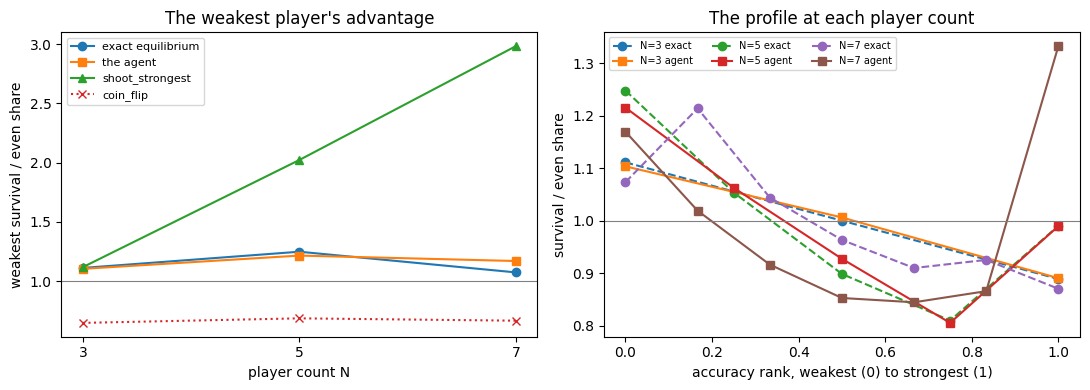

In [35]:
figure, axes = plt.subplots(1, 2, figsize=(11, 4))

counts = PLAYER_COUNTS
axes[0].plot(counts, [EXACT[n][sorted(EXACT[n])[0]] / UNIFORM[n] for n in counts],
             marker="o", label="exact equilibrium")
axes[0].plot(counts, [agent_ratios[n] for n in counts], marker="s", label="the agent")
axes[0].plot(counts, [reference_ratios[("shoot_strongest", n)] for n in counts],
             marker="^", label="shoot_strongest")
axes[0].plot(counts, [reference_ratios[("coin_flip", n)] for n in counts],
             marker="x", linestyle=":", label="coin_flip")
axes[0].axhline(1.0, color="grey", linewidth=0.8)
axes[0].set_xlabel("player count N")
axes[0].set_ylabel("weakest survival / even share")
axes[0].set_title("The weakest player's advantage")
axes[0].set_xticks(counts)
axes[0].legend(fontsize=8)

for n in counts:
    ranked_exact = [EXACT[n][a] / UNIFORM[n] for a in sorted(EXACT[n])]
    ranked_measured = [POOLED[n][a] / UNIFORM[n] for a in sorted(POOLED[n])]
    positions = [index / (len(ranked_exact) - 1) for index in range(len(ranked_exact))]
    axes[1].plot(positions, ranked_exact, marker="o", linestyle="--",
                 label="N=%d exact" % n)
    axes[1].plot(positions, ranked_measured, marker="s", linestyle="-",
                 label="N=%d agent" % n)
axes[1].axhline(1.0, color="grey", linewidth=0.8)
axes[1].set_xlabel("accuracy rank, weakest (0) to strongest (1)")
axes[1].set_ylabel("survival / even share")
axes[1].set_title("The profile at each player count")
axes[1].legend(fontsize=7, ncol=3)

plt.tight_layout()
plt.show()

## Reproducibility

**Two random streams have to be reset, not one.** The environment has its own generator, and a
trained policy *samples* its actions from torch's global stream. Reseeding only the environment
leaves the policy's stream wherever the previous call left it, and the measurement then differs
for a reason that has nothing to do with the agent.

In [36]:
def measure_once():
    torch.manual_seed(7000)
    fixed_game = GruelEnv(n=5, reward=REWARD, seating=SEATING, seed=9000)
    records = play_episodes(fixed_game, make_agent_policy(models[(5, 0)]), 500)
    rates = survival_by_accuracy(records, ACCURACIES[5])
    return [round(rates[a], 6) for a in sorted(rates)]


first = measure_once()
second = measure_once()
print("first: ", first)
print("second:", second)
print("identical:", first == second)

first:  [0.268, 0.212, 0.17, 0.172, 0.178]
second: [0.268, 0.212, 0.17, 0.172, 0.178]
identical: True


## What this step establishes

In [37]:
print("1. Three player counts, three DIFFERENT exact shapes:")
for n in PLAYER_COUNTS:
    ranked = [EXACT[n][a] for a in sorted(EXACT[n])]
    best = max(range(len(ranked)), key=lambda i: ranked[i])
    worst = min(range(len(ranked)), key=lambda i: ranked[i])
    print("     N=%d best-off rank %d, worst-off rank %d" % (n, best, worst))

print()
print("2. The gate, applied unchanged at each count:")
for n in PLAYER_COUNTS:
    print("     N=%d pooled %s, %d of %d seeds reach %.2f"
          % (n, "PASS" if gate_verdicts[n] else "FAIL",
             seed_gate_counts[n], len(SEEDS), GATE_THRESHOLD))

print()
print("3. The ordering recovered at each count:")
for n in PLAYER_COUNTS:
    print("     N=%d %s" % (n, "yes" if orderings_match[n] else "NO"))

print()
print("4. The weakest player's advantage does not grow with N in the exact answer:")
print("     exact  %s" % "  ".join("%.3f" % (EXACT[n][sorted(EXACT[n])[0]] / UNIFORM[n])
                                   for n in PLAYER_COUNTS))
print("     agent  %s" % "  ".join("%.3f" % agent_ratios[n] for n in PLAYER_COUNTS))
print("     ss     %s" % "  ".join("%.3f" % reference_ratios[("shoot_strongest", n)]
                                   for n in PLAYER_COUNTS))
print()
print("5. Between N=5 and N=7 the agent's ratio is: %s" % direction)
print()
print("6. Where the counts differ, and what it took to see it:")
print("     targeting is U-shaped at N=5 AND at N=7, so the agent learned a structured")
print("     policy at both. Compared at equal survivor counts it agrees to within %.2f at" % CLOSE)
print("     %s alive and differs at %s."
      % (" and ".join(str(a) for a in agree) if agree else "no count",
         " and ".join(str(a) for a in diverge) if diverge else "no count"))
print("     And at N=7 every middle rank sits below BOTH extremes, which is not true at")
print("     N=3 or N=5: the agent over-serves the two ends and under-serves the middle.")
print()
print("7. The budget probe at N=7, one seed: worst ratio %.3f at %d updates against %.3f"
      % (probe_worst, PROBE_UPDATES, baseline_worst))
print("     at %d. Reported as a probe, not as a gate." % UPDATES)
print()
print("   A ratio that climbs at every step is shoot_strongest's signature, not evidence of")
print("   good play. Which is why this folder gates on reproducing the exact PROFILE and")
print("   measures WHO the agent shoots, and treats the ratio as one descriptive column.")
print()
print("   And the profile is what carried the finding here: the ratio alone would have said")
print("   'roughly flat from N=5 to N=7' and left it there. The per-rank comparison is what")
print("   showed the N=7 answer was not reproduced at all.")

1. Three player counts, three DIFFERENT exact shapes:
     N=3 best-off rank 0, worst-off rank 2
     N=5 best-off rank 0, worst-off rank 3
     N=7 best-off rank 1, worst-off rank 6

2. The gate, applied unchanged at each count:
     N=3 pooled PASS, 3 of 3 seeds reach 0.95
     N=5 pooled PASS, 3 of 3 seeds reach 0.95
     N=7 pooled FAIL, 0 of 3 seeds reach 0.95

3. The ordering recovered at each count:
     N=3 yes
     N=5 yes
     N=7 NO

4. The weakest player's advantage does not grow with N in the exact answer:
     exact  1.111  1.248  1.073
     agent  1.104  1.215  1.169
     ss     1.118  2.022  2.983

5. Between N=5 and N=7 the agent's ratio is: flat

6. Where the counts differ, and what it took to see it:
     targeting is U-shaped at N=5 AND at N=7, so the agent learned a structured
     policy at both. Compared at equal survivor counts it agrees to within 0.01 at
     5 and 4 alive and differs at 3.
     And at N=7 every middle rank sits below BOTH extremes, which is no